<a href="https://colab.research.google.com/github/Shiiroi/132-Project/blob/main/Copy_of_cad4you_verilog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Verilog LAB

This lab will illustrate three Colab extensions: **\%\%verilog, \%\%print_verilog, \%\%waveform**. This section is organized as follows:

* Logic gates and Boolean expressions
* Structural Design
* Behavior Design and Waveforms
* Dump memory contents to a file

## Setup

Please execute the next cell to **setup this colab** to support **Verilog**

In [ ]:
!pip install git+https://github.com/lesc-ufv/cad4u.git
%load_ext plugin

  Cloning https://github.com/lesc-ufv/cad4u.git to /tmp/pip-req-build-_b9361kl
  Running command git clone --filter=blob:none --quiet https://github.com/lesc-ufv/cad4u.git /tmp/pip-req-build-_b9361kl
  Resolved https://github.com/lesc-ufv/cad4u.git to commit ac30b30439dfce1f2b8e12f192b8854d09ae6603
  Preparing metadata (setup.py) ... done
  Created wheel for ColabPlugin: filename=ColabPlugin-1.0-py3-none-any.whl size=19402 sha256=305c3caf49ccac61adfb9a60505187b7ec43d0a0b40be4c90525ab4876494366
  Stored in directory: /tmp/pip-ephem-wheel-cache-gbyd7gkk/wheels/e8/06/0c/dfe7f6a5c1f75826c8cfa61c097809db4eef7bb7281572edf2
Successfully built ColabPlugin


# Logic Gates and Boolean Expressions

By using **\%\%verilog** at first line, you could add Verilog code to be compiled and executed inside Colab. Next example shows a full adder described by two simple boolean expression. The testbench depicts the thruth table.

In [ ]:
%%verilog
module fulladder(a, b, c, sum, cout);
  input a,b,c;
  output sum, cout;
    assign sum = a ^ b ^ c;
    assign cout = a&b| a&c | b&c;
endmodule


module logic_testbench();
reg [2:0] counter;
wire sum,cout;
wire [1:0] d;
assign d = {cout,sum};
integer k;
	fulladder t(counter[2],counter[1],counter[0],sum,cout);
	initial begin
		$display("abc | cout sum  Decimal");
		$monitor("%3b |  %1b    %1b       %d", counter, cout, sum, d);
		counter = 0;
		for (k=1; k<8; k=k+1)
     #1 counter = k;
		$finish;
	end
endmodule

Installing. Please wait... done!
abc | cout sum  Decimal
000 |  0    0       0
001 |  0    1       1
010 |  0    1       1
011 |  1    0       2
100 |  0    1       1
101 |  1    0       2
110 |  1    0       2
111 |  1    1       3



## A structural view of your design

We also develop an extension to convert a Verilog description onto a graph. By starting with **\%\%print_verilog**, the graphical output will be generated. Next cell shows the fulladder module.

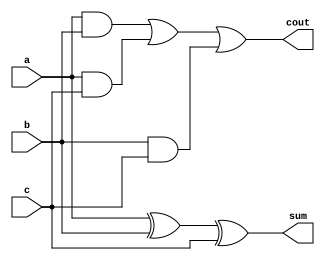

In [ ]:
%%print_verilog
module fulladder(a, b, c, sum, cout);
  input a,b,c;
  output sum, cout;
    assign sum = a ^ b ^ c;
    assign cout = a&b| a&c | b&c;
endmodule

# Structured Design

This section illustrates Verilog code based on structural design. We present a 4 bit Ripple Adder, and an array multiplier.

## Full Adder

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/5d/4-bit_ripple_carry_adder.svg/1280px-4-bit_ripple_carry_adder.svg.png" alt="wscad2020" width="400"/>



In [ ]:
%%verilog
module fulladder(a, b, cin, sum, cout);
input a,b,cin;
output sum,cout;
 assign sum = cin ^ a ^ b;
 assign cout = (a&b)|(cin&(a^b));
endmodule

module add4bits(input [3:0]a, input [3:0]b, output [3:0]s);
wire [3:0]v;
fulladder m0(a[0],b[0],1'b0,s[0],v[0]);
fulladder m1(a[1],b[1],v[0],s[1],v[1]);
fulladder m2(a[2],b[2],v[1],s[2],v[2]);
fulladder m3(a[3],b[3],v[2],s[3],v[3]);
endmodule

module logic_testbench();
reg [3:0] a, b;
wire [3:0] sum;
	add4bits A(a,b,sum);
	initial begin
		$display(" a +  b = sum ");
		#1 a=3; b=4;
		$monitor("%d + %d = %d", a,b,sum);
		 #1 a=4; b=4;
     #1 a=7; b=5;
		$finish;
	end
endmodule

Installing. Please wait... done!
 a +  b = sum 
 3 +  4 =  7
 4 +  4 =  8
 7 +  5 = 12



## Array Multiplier

![](https://tams.informatik.uni-hamburg.de/applets/hades/webdemos/20-arithmetic/60-mult/mult4x4.gif)

In [ ]:
%%verilog

module fulladder(a, b, cin, sum, cout);
input a,b,cin;
output sum,cout;
 assign sum = cin ^ a^b;
 assign cout = (a&b)|(cin&(a^b));
endmodule

module andadd(si,a,b,ci,so,co);
input si,a,b,ci;
output so,co;
wire A;
assign A = a&b;
fulladder ADD(A,si,ci,so,co);
endmodule


module mul4bits(input [3:0]a, input [3:0]b, output [7:0]p);
wire [3:0] ls0,lc0;
andadd m00(1'b0,a[0],b[0],1'b0,p[0],lc0[0]);
andadd m01(1'b0,a[1],b[0],1'b0,ls0[1],lc0[1]);
andadd m02(1'b0,a[2],b[0],1'b0,ls0[2],lc0[2]);
andadd m03(1'b0,a[3],b[0],1'b0,ls0[3],lc0[3]);
wire [3:0] ls1,lc1;
andadd m10(ls0[1],a[0],b[1],lc0[0],p[1],lc1[0]);
andadd m11(ls0[2],a[1],b[1],lc0[1],ls1[1],lc1[1]);
andadd m12(ls0[3],a[2],b[1],lc0[2],ls1[2],lc1[2]);
andadd m13(1'b0,a[3],b[1],lc0[3],ls1[3],lc1[3]);
wire [3:0] ls2,lc2;
andadd m20(ls1[1],a[0],b[2],lc1[0],p[2],lc2[0]);
andadd m21(ls1[2],a[1],b[2],lc1[1],ls2[1],lc2[1]);
andadd m22(ls1[3],a[2],b[2],lc1[2],ls2[2],lc2[2]);
andadd m23(1'b0,a[3],b[2],lc1[3],ls2[3],lc2[3]);
wire [3:0] ls3, lc3;
andadd m30(ls2[1], a[0], b[3], lc2[0], p[3], lc3[0]);
andadd m31(ls2[2], a[1], b[3], lc2[1], ls3[1], lc3[1]);
andadd m32(ls2[3], a[2], b[3], lc2[2], ls3[2], lc3[2]);
andadd m33(1'b0, a[3], b[3], lc2[3], ls3[3], lc3[3]);
wire [3:0] c;
fulladder l40(ls3[1],lc3[0],1'b0,p[4],c[0]);
fulladder l41(ls3[2],lc3[1],c[0],p[5],c[1]);
fulladder l42(ls3[3],lc3[2],c[1],p[6],c[2]);
fulladder l43(1'b0,lc3[3],c[2],p[7],c[3]);
endmodule

module logic_testbench();
reg [3:0] a;
reg [3:0] b;
wire [7:0] p;
	mul4bits A(a,b,p);
	initial begin
		$display(" a *  b | mult ");
		#1 a=6; b=6;
		$monitor("%d *  %d = %d", a,b,p);
		 #1 a=4; b=4;
     #1 a=7; b=7;
		$finish;
	end
endmodule

 a *  b | mult 
 6 *   6 =  36
 4 *   4 =  16
 7 *   7 =  49



# Behavior Design and Waveforms

This section presents an  example of behavior description by using a counter to illustrate how to use the **\%\%waveform** extension.

## Counter

This example describes a 4-bit counter by using behavior code. The signal values will be dumpped in the **test.vcd file**. First, execute the next cell, and then the following cell will draw the waveforms.

In [ ]:
%%verilog
module counter(input clk,  input rst_n,  output reg [4:0] count);
always @(posedge clk, negedge rst_n)
  if (~rst_n)
    count <= 4'b0;
  else
    count <= count + 1'b1;
endmodule

module tb();
reg clk,rst;
wire [4:0] count;

counter c(clk,rst,count);

initial begin
  clk=0;
     forever #1 clk = ~clk;
end

initial begin
$dumpfile("test.vcd");
$dumpvars;
 rst <= 0;
 #2;
 rst <= 1;
 #20;
 $dumpoff;
 $finish;
end
endmodule


VCD info: dumpfile test.vcd opened for output.



## Waveform
 We develop the **\%\%waveform** extension. The user should specify the **vcd** file, the initial and end time, the signal list to be displayed as shown for our counter example. In addition, the number could be displayed in binary, octal, hexagonal, decimal or complement of two format.

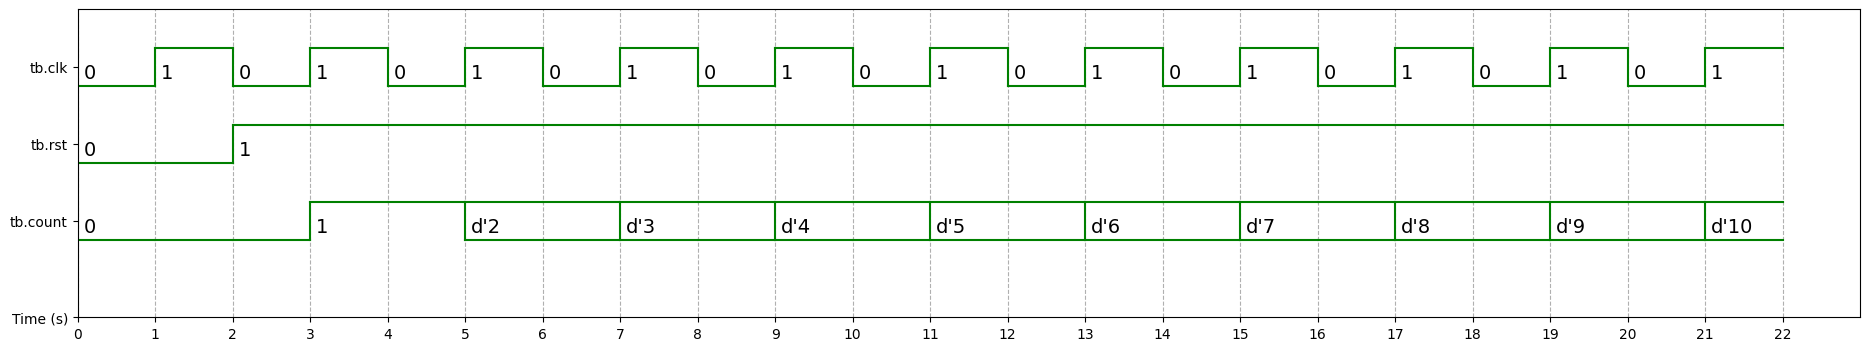

In [ ]:
%%waveform test.vcd

sign_list = ['tb.clk','tb.rst', 'tb.count']
time_begin = 0
time_end = 22
base = 'dec' # bin, dec, dec2, hex, octal

# Write the RAM simulation results in a file

This last example shows a RAM memoty model code and how to dump the RAM contents into a file, and then show it.

In [ ]:
%%verilog
module memory (input [4:0] addr, input [3:0] writedata, input memread, memwrite, clk, output [3:0] readdata);
 integer i;
 reg [3:0] memory [0:31]; // *** MEMORY ***
  // fill the memory
  initial begin
    for (i = 0; i <= 31; i++)
      memory[i] <= 0;
  end
  assign readdata = (memread) ? memory[addr] : 0;
  always @(posedge clk) begin
    if (memwrite)
      memory[addr] <= writedata;
	end
endmodule

module tb();
reg [4:0] address;
reg [3:0] writedata;
reg clk,memread,memwrite;
wire [3:0] readdata;
integer k;

memory M(address, writedata, memread, memwrite, clk, readdata);

initial begin
  clk=0;
     forever #1 clk = ~clk;
end
initial begin
memwrite = 0; memread= 0; address = 0; #2
writedata =  4; address = 3; memread= 1; #2
memwrite = 1; #2
memwrite = 0; writedata =  5; address = 5; #2
memwrite = 1; #2
$writememh("mem.data", tb.M.memory, 0, 15);
$finish;
end
endmodule


Installing. Please wait... done!



In [ ]:
# Execute this cell to show RAM file
!cat mem.data

// 0x00000000
0
0
0
4
0
5
0
0
0
0
0
0
0
0
0
0


Installing pip dependecies. Please wait... done!
VCD info: dumpfile dump.vcd opened for output.



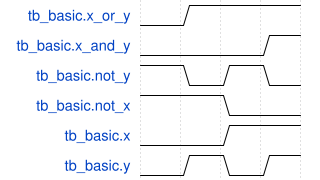

In [ ]:
%%wavedrom
module tb_basic;
  reg x, y;
  wire x_and_y, x_or_y, not_x, not_y;

  basic dut(x, y, x_and_y, x_or_y, not_x, not_y);

  initial begin
    $dumpvars(0);
  end

  initial begin
    x = 1'b0; y = 1'b0; #10
    x = 1'b0; y = 1'b1; #10
    x = 1'b1; y = 1'b0; #10
    x = 1'b1; y = 1'b1; #10
    $finish;
  end
endmodule

module basic(
  input x, y,
  output x_and_y, x_or_y, not_x, not_y
  );

  // continuous assignment
  assign x_and_y = x & y;
  assign not_x = ~x;

  // basic primitives
  or (x_or_y, x, y);
  not (not_y, y);
endmodule